# Tutorial 1 — Perceptron and sigmoid classifier

We classify Iris-setosa versus the other Iris flowers. This completes manual prediction, both label encodings, and the sigmoid extension. The original Perceptron.py is preserved.

**How to run:** select a Python kernel with the repository requirements, then Run All. QUICK mode keeps experiments short. For the larger run set `TUTORIAL_FULL=1` before starting the kernel. A quick run demonstrates the method; it is not a final accuracy benchmark.

In [1]:
# Google Colab: fetch the support files and install missing dependencies.
# Local Jupyter: follow README setup once; this cell makes no changes.
import sys, subprocess
from pathlib import Path
if "google.colab" in sys.modules:
    repo = Path("/content/dl-course-tutorials")
    if not repo.exists():
        subprocess.check_call(["git", "clone", "https://github.com/naveed952/Tutorial-01_Perceptron_py.ipynb.git", str(repo)])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", str(repo/"requirements.txt")])
    import os
    os.chdir(repo)


## Step 1 — Locate the project and set a reproducible seed
A fixed seed makes comparisons easier to reproduce. Each notebook can run independently.

In [2]:
from pathlib import Path
import sys, os
ROOT = Path.cwd() if (Path.cwd()/"tutorial_support").exists() else Path.cwd().parent
assert (ROOT/"tutorial_support").exists(), "Run from the repository or notebooks folder."
sys.path.insert(0, str(ROOT))
from tutorial_support.common import *
seed()
print("Mode:", "QUICK: small real-data run" if QUICK else "FULL: larger training run")

Mode: QUICK: small real-data run


## Step 2 — Split first, then scale
The scaler learns only from training data. A stratified split preserves the proportions of setosa and non-setosa.

In [3]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
iris = load_iris(); X = iris.data; y = (iris.target == 0).astype(int)
Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=.25,stratify=y,random_state=SEED)
scaler = StandardScaler().fit(Xtr); Xtr = scaler.transform(Xtr); Xte = scaler.transform(Xte)
print('Train/test:',Xtr.shape,Xte.shape); print('Feature order:',list(iris.feature_names))

Train/test: (112, 4) (38, 4)
Feature order: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


## Step 3 — Implement the hard-threshold perceptron
The neuron computes z = w·x + b. For each mistake, w ← w + η(y−ŷ)x and b ← b + η(y−ŷ). The bias is a trainable threshold. A step function is not differentiated here.

0/1 accuracy: 1.0
-1/+1 accuracy: 1.0


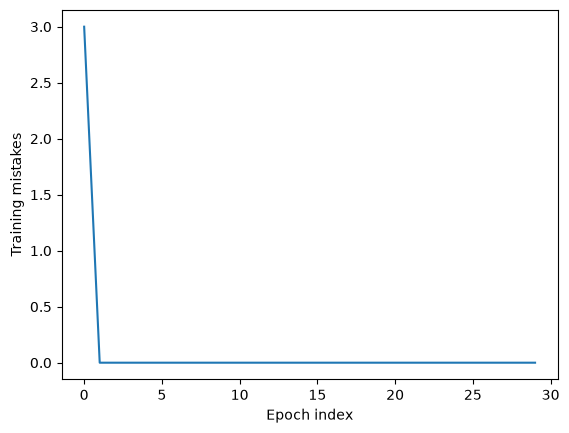

In [4]:
class Perceptron:
    def __init__(self, eta=.01, epochs=30, negative=0):
        self.eta,self.epochs,self.negative=eta,epochs,negative
    def predict(self,X):
        return np.where(np.asarray(X)@self.w+self.b >= 0,1,self.negative)
    def fit(self,X,y):
        self.w=np.zeros(X.shape[1]); self.b=0.; self.errors=[]
        for epoch in range(self.epochs):
            errors=0
            for i in np.random.default_rng(SEED+epoch).permutation(len(y)):
                update=self.eta*(y[i]-self.predict(X[i]))
                self.w += update*X[i]; self.b += update; errors += int(update != 0)
            self.errors.append(errors)
        return self
step01=Perceptron().fit(Xtr,ytr)
step_pm=Perceptron(negative=-1).fit(Xtr,2*ytr-1)
print('0/1 accuracy:',accuracy_score(yte,step01.predict(Xte)))
print('-1/+1 accuracy:',accuracy_score(2*yte-1,step_pm.predict(Xte)))
plt.plot(step01.errors); plt.xlabel('Epoch index');plt.ylabel('Training mistakes');plt.show()

## Step 4 — Replace the step with a sigmoid and a suitable loss
Thresholding sigmoid(z) at 0.5 is exactly the same boundary as z ≥ 0. To learn probabilities, use the unthresholded probability in binary cross-entropy: gradient = (p−y)x. This is logistic regression, not the original mistake-only update.

              precision    recall  f1-score   support

  not setosa       1.00      1.00      1.00        25
      setosa       1.00      1.00      1.00        13

    accuracy                           1.00        38
   macro avg       1.00      1.00      1.00        38
weighted avg       1.00      1.00      1.00        38



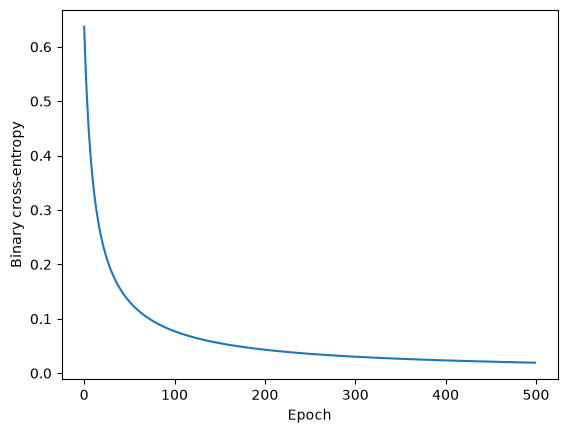

WindowsPath('D:/Disk E/Robotics And Ai/Deep  Learning/completed-tutorials/artifacts/01_perceptron.json')

In [5]:
def sigmoid(z): return 1/(1+np.exp(-np.clip(z,-50,50)))
w=np.zeros(Xtr.shape[1]); b=0.; losses=[]
for epoch in range(500):
    p=sigmoid(Xtr@w+b); error=p-ytr
    w -= .1*(Xtr.T@error)/len(ytr); b -= .1*error.mean()
    p=sigmoid(Xtr@w+b)
    losses.append(float(-np.mean(ytr*np.log(p+1e-9)+(1-ytr)*np.log(1-p+1e-9))))
pred=(sigmoid(Xte@w+b)>=.5).astype(int)
print(classification_report(yte,pred,target_names=['not setosa','setosa']))
plt.plot(losses);plt.xlabel('Epoch');plt.ylabel('Binary cross-entropy');plt.show()
assert losses[-1]<losses[0]
save_result('01_perceptron',{'step_accuracy':accuracy_score(yte,step01.predict(Xte)), 'sigmoid_accuracy':accuracy_score(yte,pred)})

## Step 5 — Complete the manual-input task
Edit these four measurements in centimetres, in the printed feature order. We use a cell instead of blocking input() so Run All remains reproducible.

In [6]:
manual_measurements=[5.1,3.5,1.4,.2]
assert len(manual_measurements)==4 and all(v>0 for v in manual_measurements)
manual=scaler.transform([manual_measurements]); prob=float(sigmoid(manual@w+b)[0])
print('Prediction:', 'Iris-setosa' if prob>=.5 else 'Not Iris-setosa', '| probability:',round(prob,4))

Prediction: Iris-setosa | probability: 0.9943


## Task discussion
A correct hard prediction produces zero perceptron update. A sigmoid model can still update a correct but uncertain prediction. Neither single linear boundary can solve XOR; adding a nonlinear hidden layer is the next tutorial.

## Explain it in class
Describe the input, target, model, loss, update rule and evaluation split. Use the displayed results from your own run. Changing the dataset, seed or training budget can change the result.

**Course source:** the matching tutorial PDF supplied in the Deep Learning course. Original explanatory implementation; the course PDFs are not redistributed.